In [36]:
import os
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from simulation.helper.time import SimulationTimeConverter

In [2]:
os.getcwd()

'/Users/janik/source/urban-mobility-simulation/resources/scripts/simulation_analysis'

In [3]:
os.chdir("../../../")
os.getcwd()

'/Users/janik/source/urban-mobility-simulation'

In [4]:
auction_tracking = pd.read_csv("data/output/tracking/auction.csv")

In [5]:
auction_tracking

,time,timeslot,location,results.capacity,results.clearing_price,bids
0,0,30,872664c1effffff,0.0,0.0,NaN
1,0,30,872664c1affffff,0.0,0.0,NaN
2,0,30,87275934effffff,0.0,0.0,NaN
3,0,30,872664cadffffff,0.0,0.0,NaN
4,0,30,872664c16ffffff,0.0,0.0,NaN
...,...,...,...,...,...,...
376,285,315,872664cf5ffffff,0.0,0.0,NaN
377,285,315,872664cacffffff,0.0,0.0,NaN
378,285,315,872664c10ffffff,0.0,0.0,NaN
379,285,315,872664d89ffffff,0.0,0.0,NaN


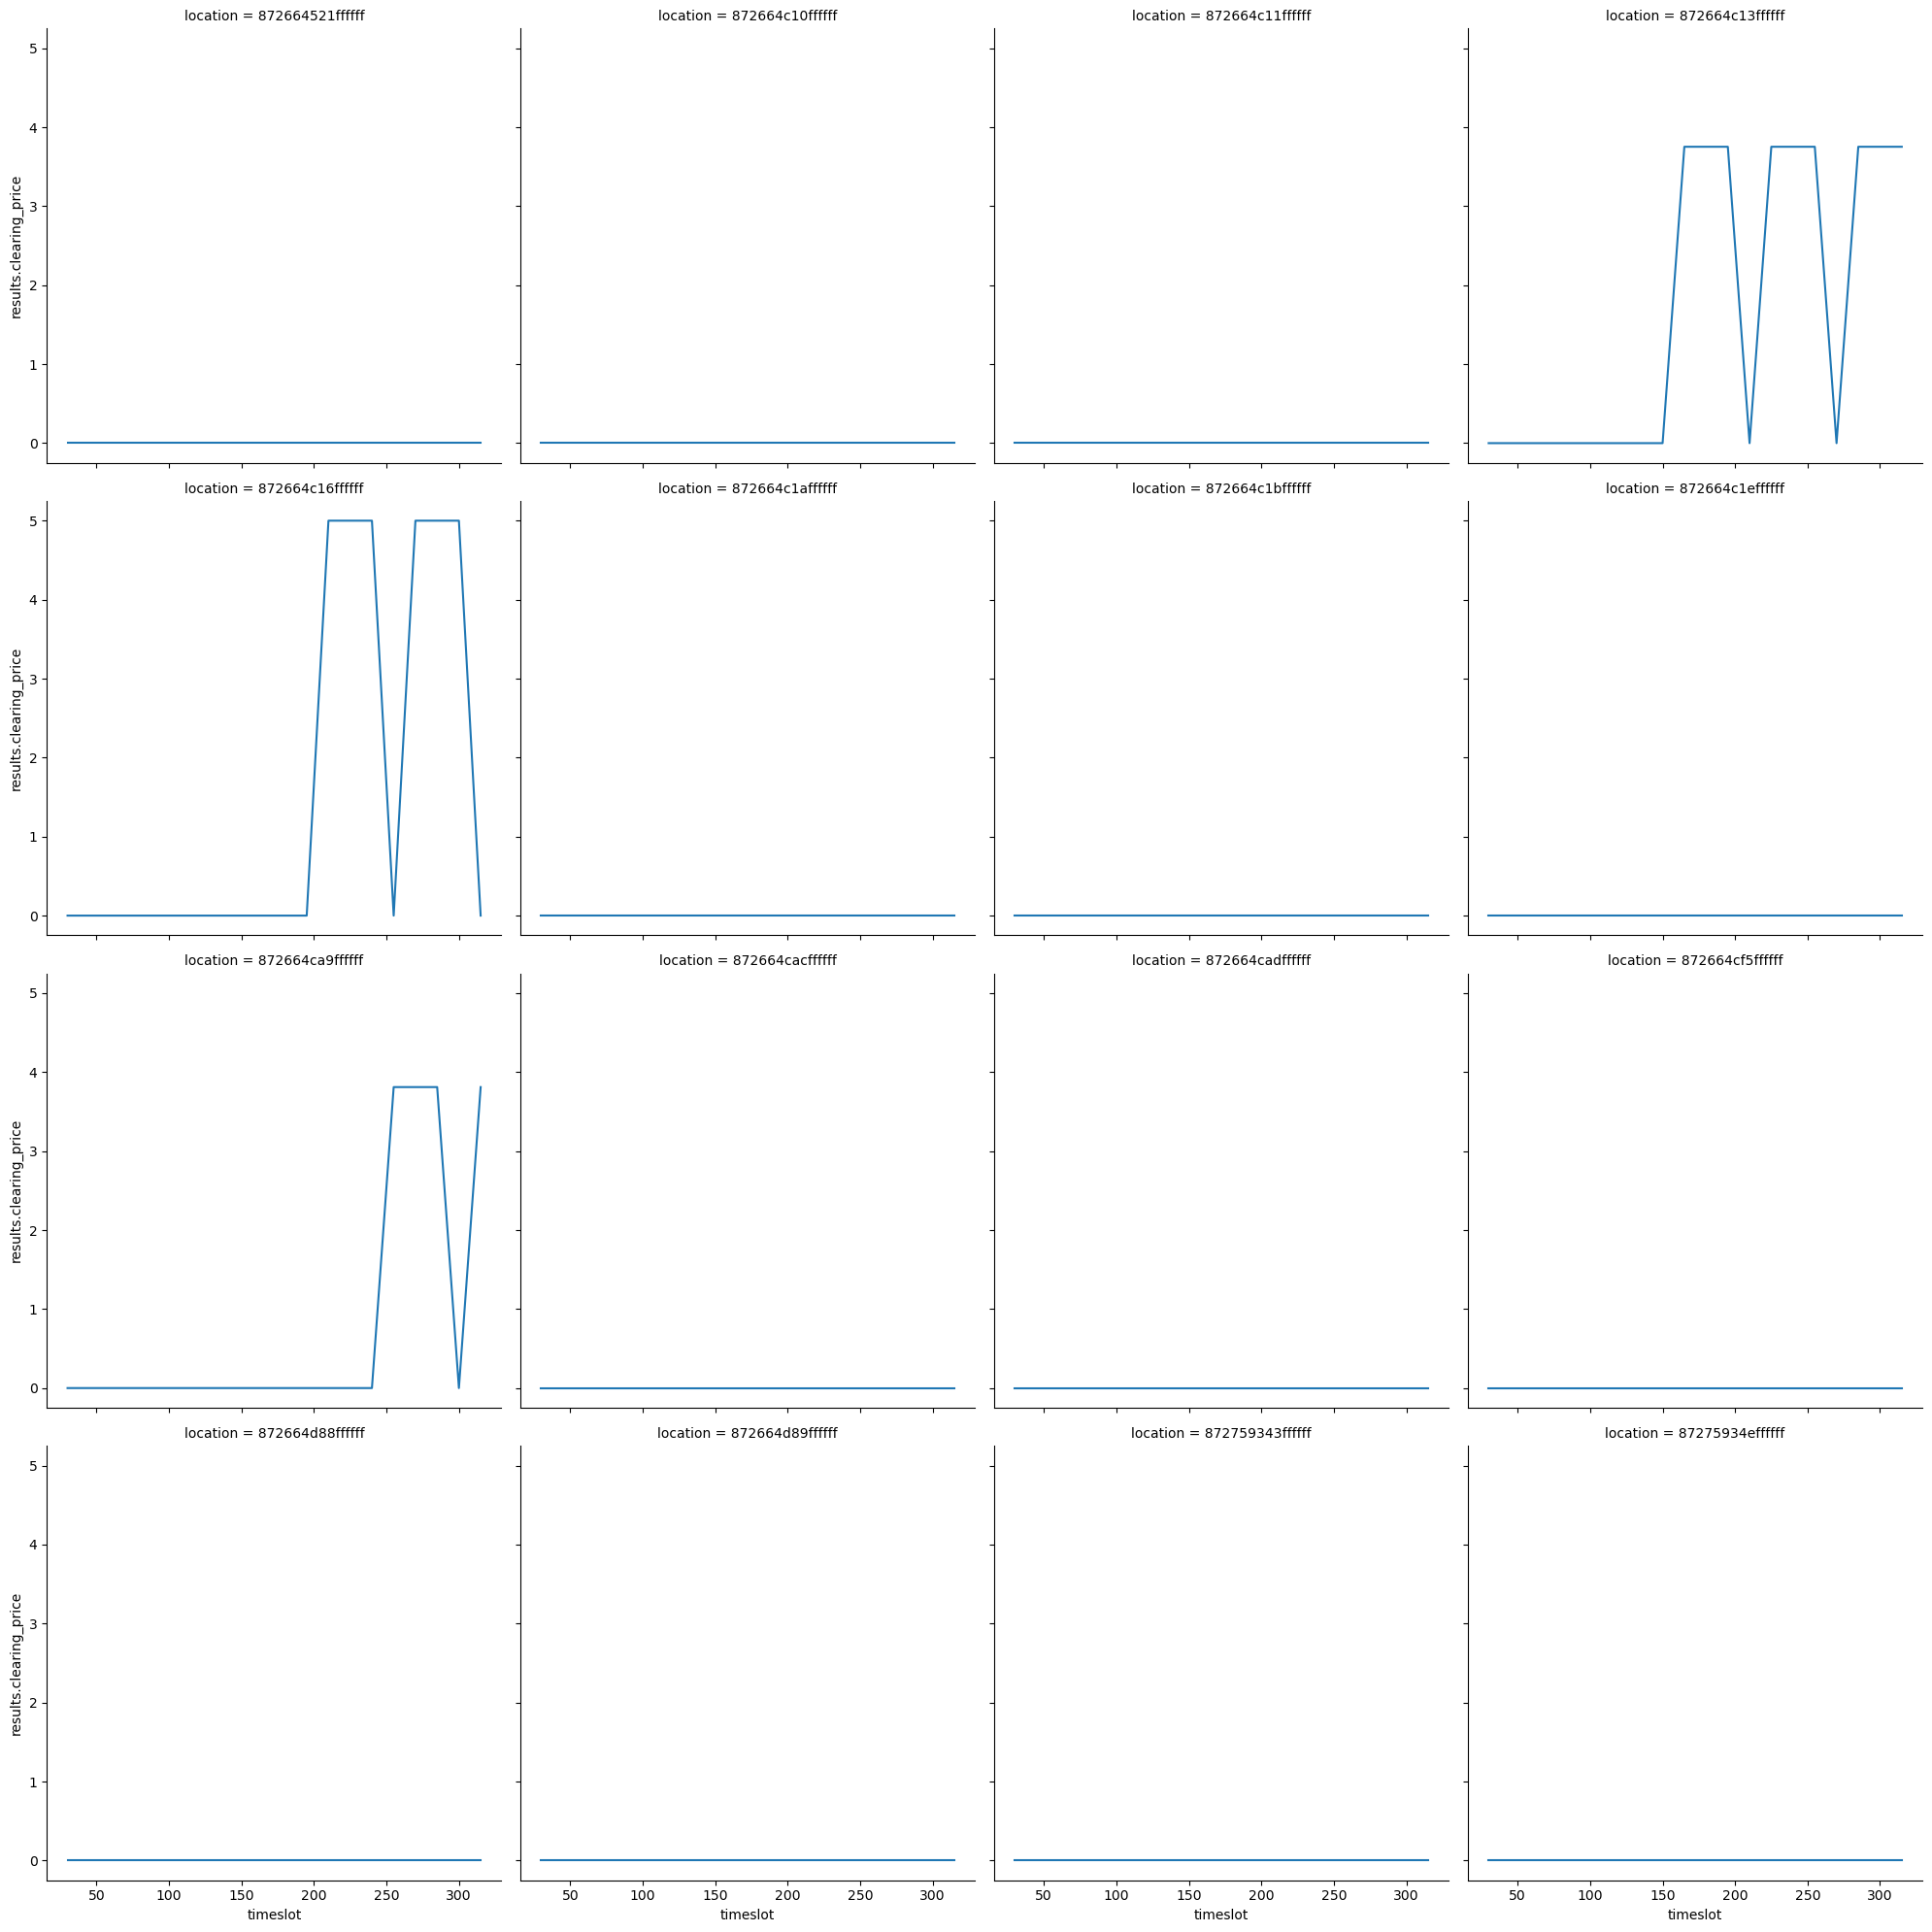

In [17]:
auction_tracking.sort_values(by=['time', 'location'], inplace=True)
sns.relplot(data=auction_tracking, x="timeslot", y="results.clearing_price", col="location", col_wrap=4, kind="line")

In [6]:
vehicle_tracking = pd.read_csv("data/output/tracking/vehicles.csv")

In [7]:
vehicle_tracking

,time,_fleet,_state,_current_state_of_charge
0,1,0,"[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...","[25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25...."
1,1,1,"[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...","[25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25...."
2,2,0,"[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...","[25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25...."
3,2,1,"[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...","[25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25...."
4,3,0,"[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...","[25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25...."
...,...,...,...,...
593,297,1,"[3, 3, 3, 2, 1, 1, 2, 2, 2, 1003, 2, 3, 2, 2, ...","[25.0, 25.0, 21.148560900376804, 47.5895569298..."
594,298,0,"[3, 3, 2, 1003, 2, 1003, 1, 2, 3, 5, 4, 5, 100...","[25.0, 25.0, 49.23942585776101, 49.18600537970..."
595,298,1,"[3, 3, 3, 2, 1001, 1, 2, 2, 2, 1003, 2, 3, 2, ...","[25.0, 25.0, 21.148560900376804, 47.5895569298..."
596,299,0,"[3, 3, 2, 2, 2, 1003, 1, 2, 3, 5, 4, 5, 1003, ...","[25.0, 25.0, 49.23942585776101, 48.73520955784..."


In [14]:
RECHARGE_THRESHOLD = 40 # ATTENTION: This is an approximation, we use dynamic ones per base region

vehicle_tracking['fleet_average_SOC'] = vehicle_tracking['_current_state_of_charge'].apply(lambda x: np.mean(eval(x)))
vehicle_tracking['fleet_number_low_SOC'] = vehicle_tracking['_current_state_of_charge'].apply(lambda x: np.count_nonzero(np.array(eval(x))< RECHARGE_THRESHOLD))

Text(0.5, 1.0, '#Vehicles Fleet with Low SOC')

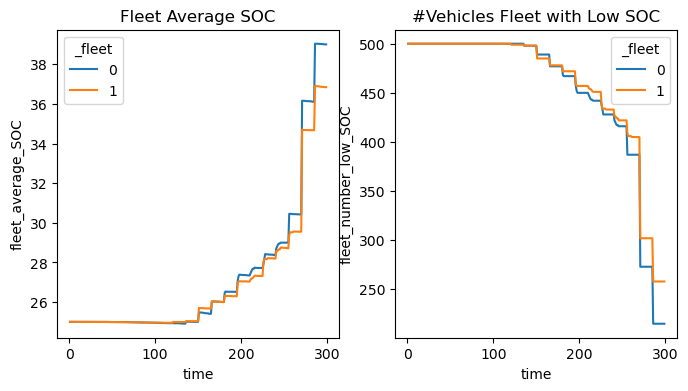

In [15]:
fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (8, 4))

sns.lineplot(data=vehicle_tracking, x='time', y='fleet_average_SOC', hue='_fleet', ax = ax[0])
sns.lineplot(data=vehicle_tracking, x='time', y='fleet_number_low_SOC', hue='_fleet', ax = ax[1])

ax[0].set_title('Fleet Average SOC')
ax[1].set_title('#Vehicles Fleet with Low SOC')

In [10]:
INITIALIZED = 0
PARKING = 1
DRIVING = 2
RELOCATING = 3
CHARGING = 4
PRE_SERVICE = 5
ONLINE = 6  # When the driver is online
OFFLINE = 7  # When the driver is offline
SOME_STATE = 1002
RESERVED = 1001
MOVING_TO_PICK_UP_POS = 1003

In [11]:
vehicle_tracking['_state_PARKING'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == PARKING))

vehicle_tracking['_state_CHARGING'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == CHARGING))

vehicle_tracking['_state_DRIVING'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == DRIVING))

Text(0.5, 1.0, 'CHARGING')

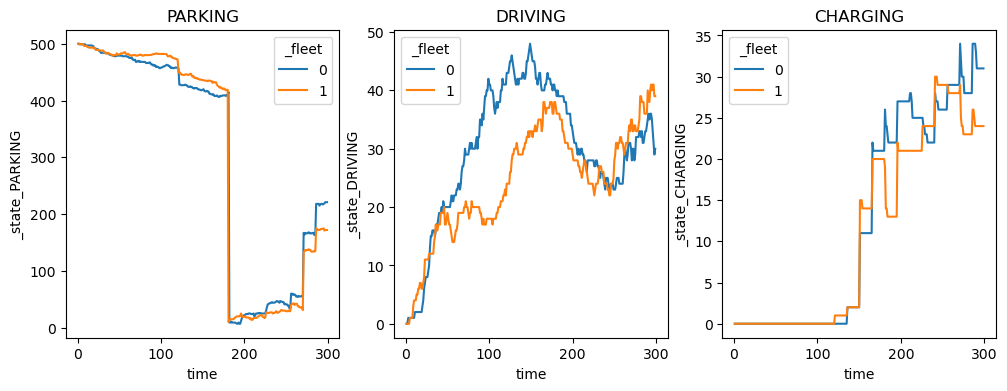

In [12]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(12, 4))
sns.lineplot(data=vehicle_tracking, x='time', y='_state_PARKING', hue='_fleet', ax=ax[0])
sns.lineplot(data=vehicle_tracking, x='time', y='_state_DRIVING', hue='_fleet', ax=ax[1])
sns.lineplot(data=vehicle_tracking, x='time', y='_state_CHARGING', hue='_fleet', ax=ax[2])

ax[0].set_title('PARKING')
ax[1].set_title('DRIVING')
ax[2].set_title('CHARGING')

In [9]:
charging_station_tracking = pd.read_csv("data/output/tracking/charging_stations.csv")

In [10]:
CHARGING_STATION_CAPACITY = 20

In [11]:
charging_station_tracking['utilization'] = charging_station_tracking['_plugs.count'] / CHARGING_STATION_CAPACITY

charging_station_tracking['system_wide_utilization'] = charging_station_tracking.groupby('time')['utilization'].transform('mean')

<Axes: xlabel='time', ylabel='system_wide_utilization'>

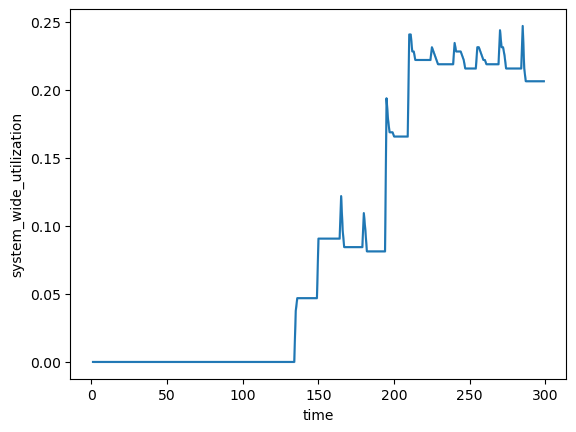

In [12]:
sns.lineplot(data=charging_station_tracking, x='time', y='system_wide_utilization')

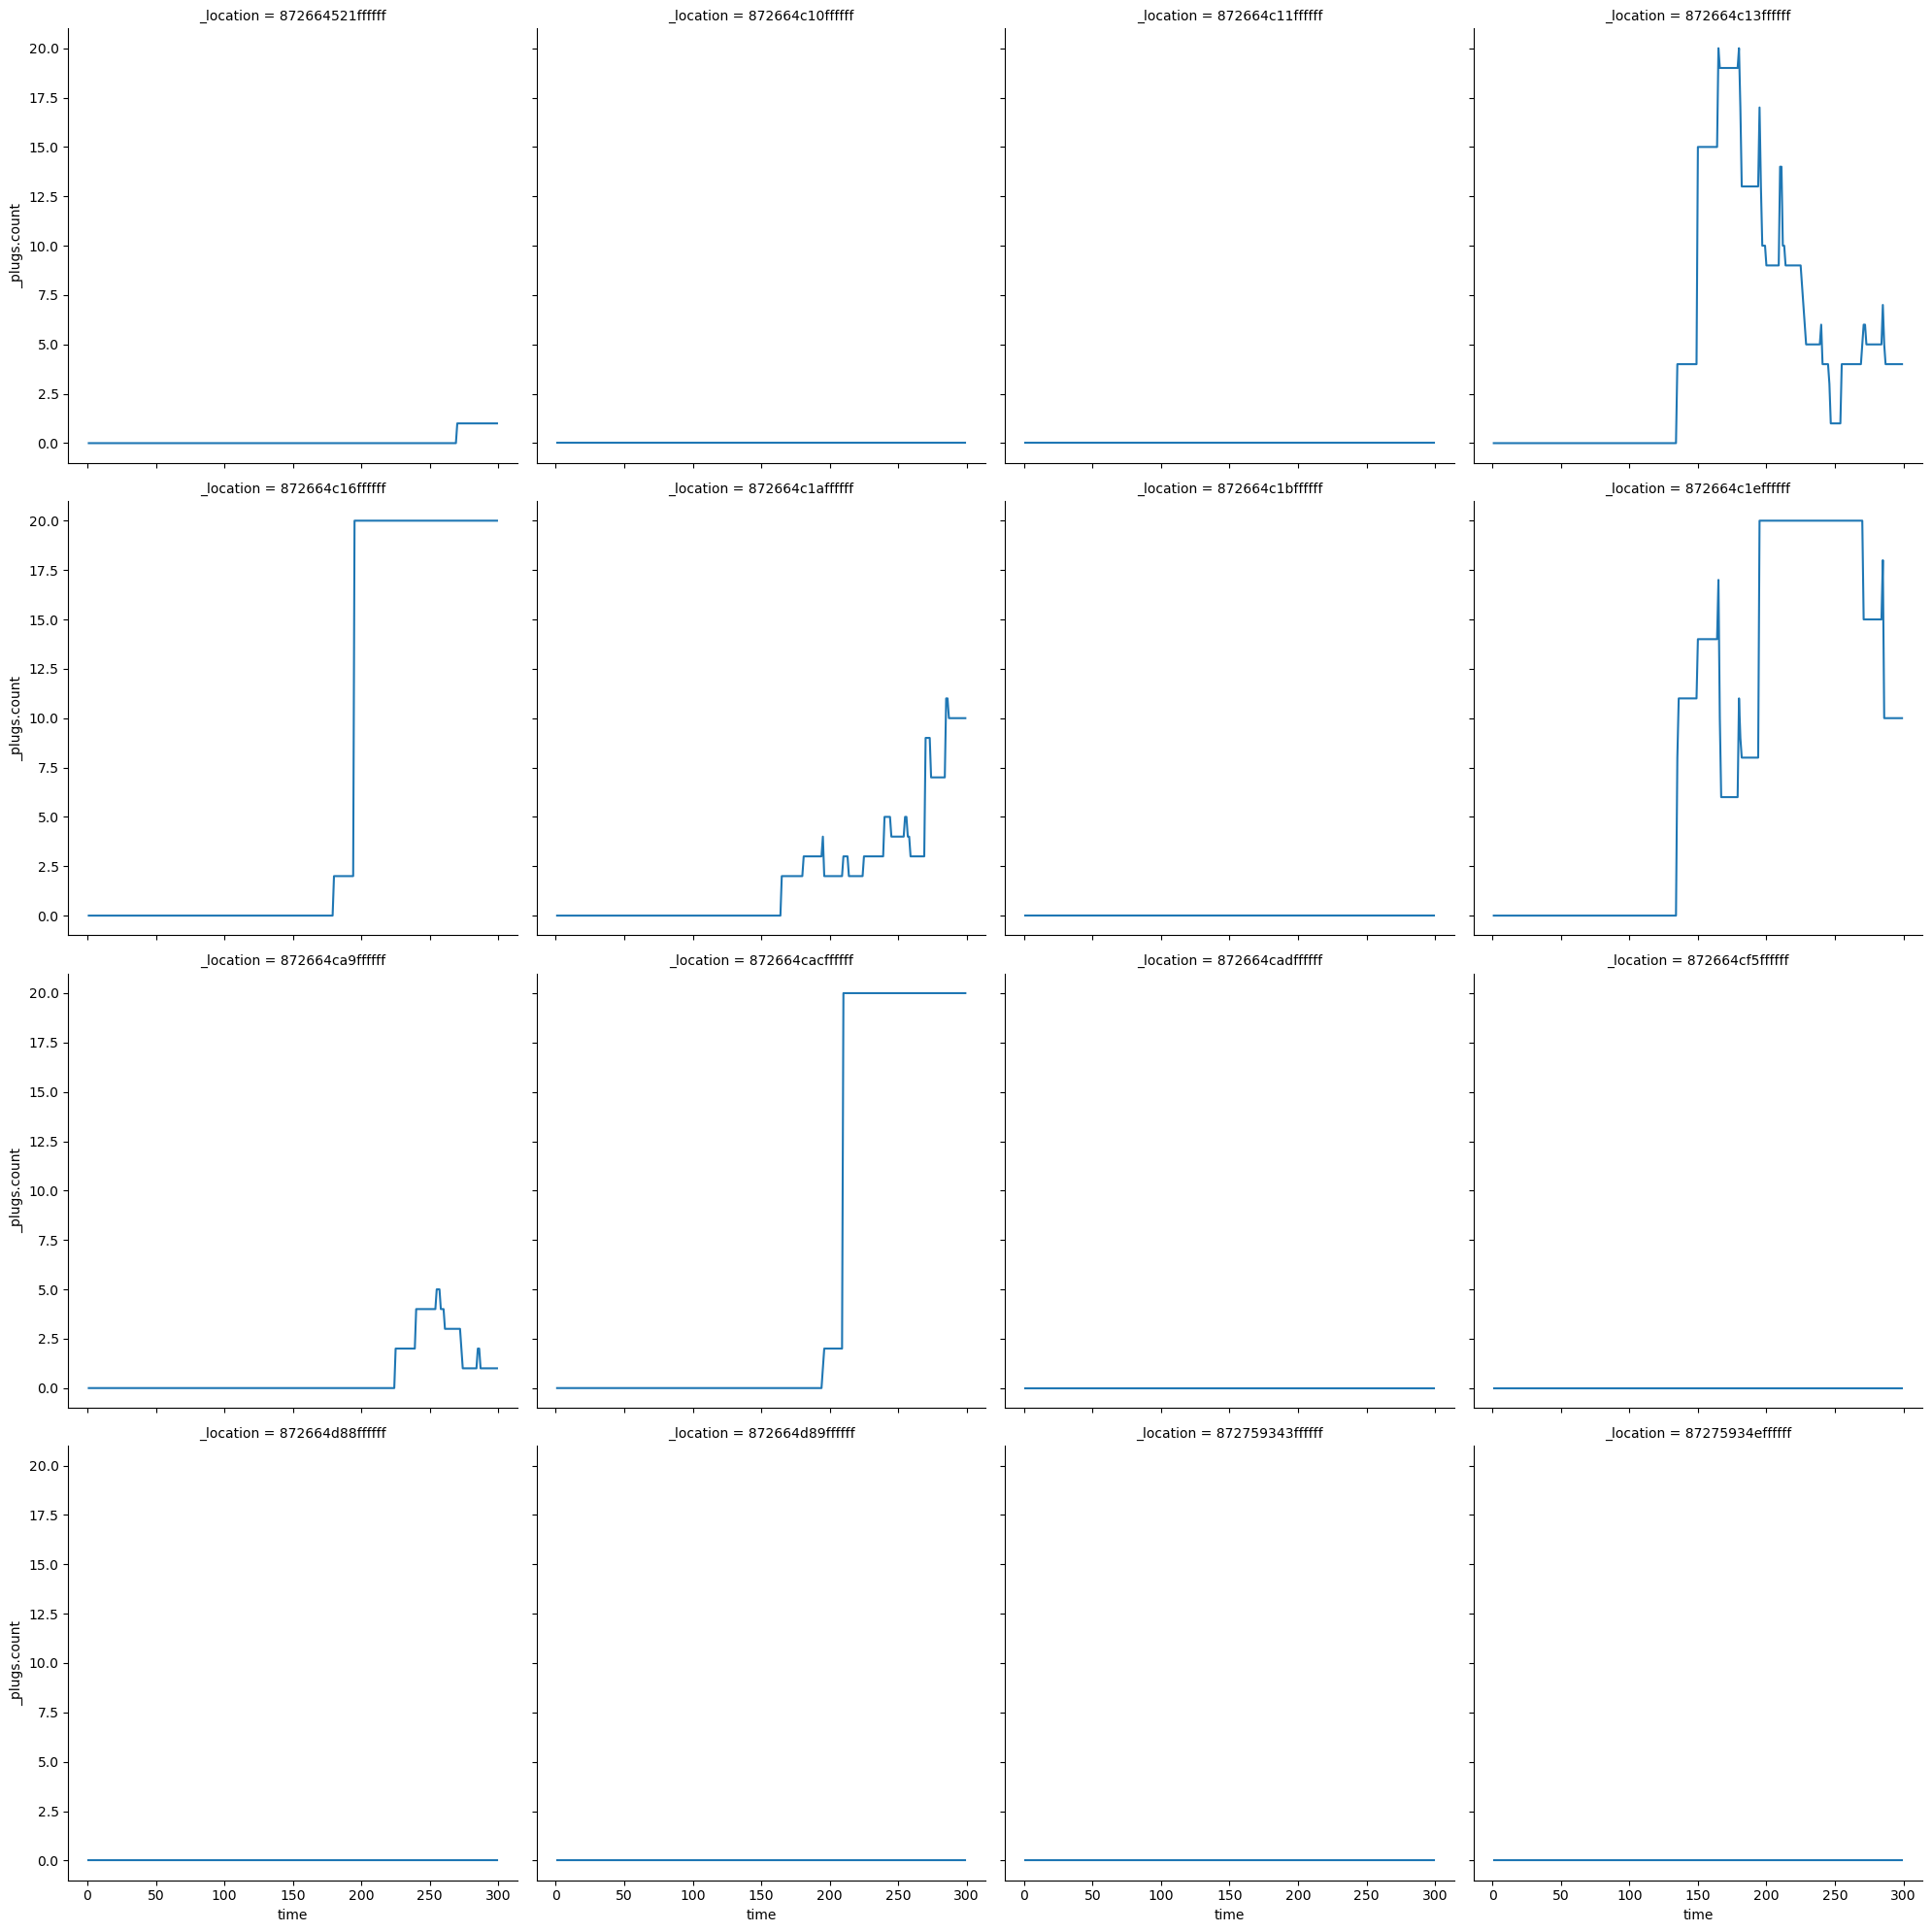

In [15]:
charging_station_tracking.sort_values(by=['time', '_location'], inplace=True)
sns.relplot(
    data=charging_station_tracking, x='time', y='_plugs.count', col='_location', kind='line', col_wrap=4)

## Transactions

In [66]:
transactions_fleet_0 = pd.read_csv("data/output/transactions/fleet_0_transactions.csv")
transactions_fleet_1 = pd.read_csv("data/output/transactions/fleet_1_transactions.csv")

In [84]:
RESAMPLE_RATE = '1h'

In [85]:
transactions_fleet_0['timestamp'] = transactions_fleet_0['time_start'].apply(SimulationTimeConverter.as_time)
transactions_fleet_0['timestamp'] = pd.to_datetime(transactions_fleet_0['timestamp'], format="%H:%M:%S")
transactions_fleet_0_resampled = transactions_fleet_0.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

transactions_fleet_1['timestamp'] = transactions_fleet_1['time_start'].apply(SimulationTimeConverter.as_time)
transactions_fleet_1['timestamp'] = pd.to_datetime(transactions_fleet_1['timestamp'], format="%H:%M:%S")
transactions_fleet_1_resampled = transactions_fleet_1.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

In [86]:
# normalize
transactions_fleet_0_resampled = transactions_fleet_0_resampled.div(transactions_fleet_0_resampled.sum(axis=1), axis=0)

transactions_fleet_1_resampled = transactions_fleet_1_resampled.div(transactions_fleet_1_resampled.sum(axis=1), axis=0)

# rename time axis
transactions_fleet_0_resampled.index = transactions_fleet_0_resampled.index.strftime("%H:%M")

transactions_fleet_1_resampled.index = transactions_fleet_1_resampled.index.strftime("%H:%M")

<Axes: xlabel='timestamp'>

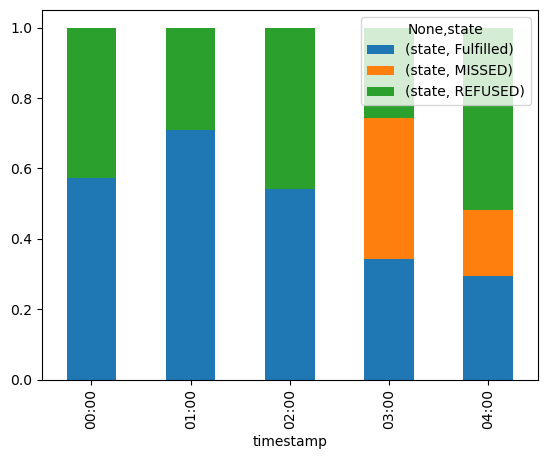

In [87]:
transactions_fleet_0_resampled.plot(kind = 'bar', stacked=True)

<Axes: xlabel='timestamp', ylabel='service_rate'>

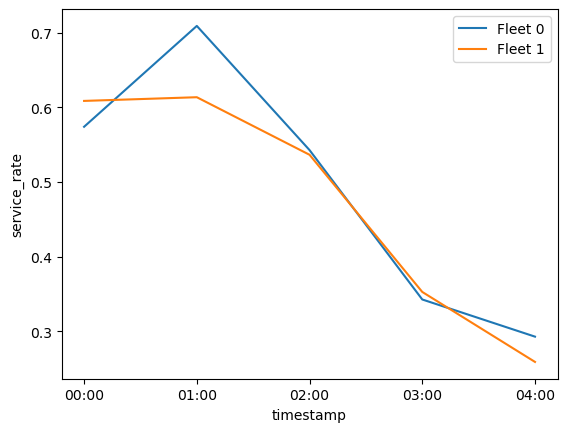

In [97]:
transactions_fleet_0_resampled['service_rate'] = transactions_fleet_0_resampled[('state', 'Fulfilled')]
transactions_fleet_1_resampled['service_rate'] = transactions_fleet_1_resampled[('state', 'Fulfilled')]

# service_rate_mean = transactions_fleet_0_resampled.reset_index()[['timestamp', 'service_rate']].join(transactions_fleet_1_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')

sns.lineplot(data=transactions_fleet_0_resampled, x = 'timestamp', y = 'service_rate', label='Fleet 0')
sns.lineplot(data=transactions_fleet_1_resampled, x = 'timestamp', y = 'service_rate', label='Fleet 1')